# Домашняя работа №2. Прогнозирование продаж

На данных Online Retail прогнозирую продажи товара REGENCY CAKESTAND 3 TIER (StockCode 22423). Сравниваю четыре модели на дневном, недельном и месячном рядах.


## 1. Подготовка данных


In [75]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from lightgbm import LGBMRegressor

plt.rcParams['figure.figsize'] = (11, 4)
plt.rcParams['axes.grid'] = True

stock_code = '22423'


def prepare_sales(df):
    valid = (
        ~df['InvoiceNo'].fillna('').str.startswith('C')
        & df['InvoiceDate'].notna()
        & df['StockCode'].notna()
        & (df['Quantity'] > 0)
        & (df['UnitPrice'] > 0)
    )
    sales = df.loc[valid].copy()
    sales['date'] = pd.to_datetime(sales['InvoiceDate']).dt.normalize()
    return sales


def get_series(sales):
    item = sales.loc[sales['StockCode'] == stock_code]
    dates = pd.date_range(sales['date'].min(), sales['date'].max(), freq='D')
    shop_days = sales['date'].unique()

    daily = item.groupby('date')['Quantity'].sum().reindex(dates).astype(float)
    daily.loc[daily.isna() & daily.index.isin(shop_days)] = 0
    weekly = daily.resample('W-SUN').sum(min_count=1)
    monthly = daily.resample('MS').sum(min_count=1)
    return daily, weekly, monthly


data_files = list(Path('/kaggle/input').rglob('Online Retail.xlsx')) if Path('/kaggle/input').exists() else []
if not data_files:
    data_files = list(Path('data').rglob('Online Retail.xlsx'))
if not data_files:
    raise FileNotFoundError('Подключите в Kaggle датасет Online Retail с файлом Online Retail.xlsx')
data_file = data_files[0]
raw = pd.read_excel(data_file, dtype={'InvoiceNo': str, 'StockCode': str})
sales = prepare_sales(raw)
daily, weekly, monthly = get_series(sales)

print('Исходных строк:', len(raw))
print('Дневных наблюдений:', daily.notna().sum(), 'из', len(daily))
print('Недель:', len(weekly), '| Месяцев:', len(monthly))


Исходных строк: 541909
Дневных наблюдений: 305 из 374
Недель: 54 | Месяцев: 13


Для недельного ряда беру самый длинный непрерывный участок полных календарных недель. Для месячного : декабрь 2010 - ноябрь 2011 года, поскольку декабрь 2011 года неполный.


In [76]:
def longest_part(s):
    groups = s.notna().ne(s.notna().shift()).cumsum()
    parts = [part for _, part in s.dropna().groupby(groups[s.notna()])]
    return max(parts, key=len)


week_full = weekly.loc[
    (weekly.index - pd.Timedelta(days=6) >= daily.index.min())
    & (weekly.index <= daily.index.max())
]
week_full = longest_part(week_full)

month_full = monthly.loc[
    (monthly.index >= daily.index.min())
    & (monthly.index + pd.offsets.MonthEnd(0) <= daily.index.max())
]

series = {'День': daily, 'Неделя': week_full, 'Месяц': month_full}
horizons = {'День': [1, 7, 31, 61], 'Неделя': [1, 4, 8], 'Месяц': [1, 2]}


def split_series(s, test_size):
    return s.iloc[:-test_size].copy(), s.iloc[-test_size:].copy()


def fill_train(s, name):
    s = s.copy()
    if name == 'День':
        for day in range(7):
            mask = (s.index.dayofweek == day) & s.isna()
            value = s.loc[(s.index.dayofweek == day) & s.notna()].median()
            s.loc[mask] = 0 if pd.isna(value) else value
    return s.ffill().bfill()


train = {}
test = {}
train_ready = {}
for name, s in series.items():
    train[name], test[name] = split_series(s, max(horizons[name]))
    train_ready[name] = fill_train(train[name], name)
    assert len(train_ready[name]) > max(horizons[name])
    assert train[name].index.max() < test[name].index.min()
    assert train_ready[name].notna().all()

print(pd.DataFrame({
    name: {'Обучение': len(train[name]), 'Тест': len(test[name]),
           'Первый тестовый период': str(test[name].index[0].date())}
    for name in series
}).T.to_string())

       Обучение Тест Первый тестовый период
День        313   61             2011-10-10
Неделя       40    8             2011-10-16
Месяц        10    2             2011-10-01


Дневные пропуски при обучении заполняю медианой соответствующего дня недели, субботы  нулями. Значения для заполнения рассчитываю только по обучающим данным.

На тесте пропуски не заполняю и считаю метрики только по известным продажам. Недельные и месячные суммы могут быть неполными из-за пропущенных дат.


## 2. Модели

Сравниваю Naive, Holt–Winters, SARIMA и LightGBM. Naive использую как базовый прогноз.

Holt–Winters и SARIMA учитывают недельную сезонность на дневном ряду. Для недельного и месячного рядов использую несезонные варианты: Holt и ARIMA. LightGBM обучаю на лагах, скользящем среднем и календарных признаках; прогноз строю рекурсивно.

Параметры фиксирую без подбора на тесте. Для месячного ряда доступно только 10 обучающих месяцев.


In [77]:
lags = {'День': [1, 2, 7, 14], 'Неделя': [1, 2, 4, 8], 'Месяц': [1, 2, 3]}
windows = {'День': 7, 'Неделя': 4, 'Месяц': 3}


def features(history, date, name):
    values = list(history)
    row = {f'lag_{k}': values[-k] for k in lags[name]}
    row['rolling_mean'] = np.mean(values[-windows[name]:])
    if name == 'День':
        row['weekday'] = date.dayofweek
        row['month'] = date.month
    elif name == 'Неделя':
        row['month'] = date.month
    else:
        row['month'] = date.month
    return row


def predict_hw(s, name, steps):
    period = 7 if name == 'День' else None
    fit = ExponentialSmoothing(
        s.to_numpy(), trend='add', damped_trend=True,
        seasonal='add' if period else None,
        seasonal_periods=period,
        initialization_method='estimated'
    ).fit(optimized=True)
    return np.maximum(np.asarray(fit.forecast(steps)), 0)


def predict_sarima(s, name, steps):
    orders = {'День': (1, 0, 1), 'Неделя': (1, 0, 1), 'Месяц': (1, 0, 0)}
    seasonal = (1, 0, 0, 7) if name == 'День' else (0, 0, 0, 0)
    model = SARIMAX(
        s.to_numpy(), order=orders[name], seasonal_order=seasonal,
        trend='c', enforce_stationarity=False, enforce_invertibility=False
    )
    fit = model.fit(disp=False, maxiter=150)
    return np.maximum(np.asarray(fit.forecast(steps)), 0)


def fit_lightgbm(s, name):
    min_history = max(max(lags[name]), windows[name])
    rows = [features(s.iloc[:i], s.index[i], name)
            for i in range(min_history, len(s))]
    x = pd.DataFrame(rows)
    y = s.iloc[min_history:].to_numpy()
    model = LGBMRegressor(
        n_estimators=120, learning_rate=0.05, max_depth=3,
        num_leaves=7, min_child_samples=2,
        verbosity=-1, n_jobs=1, random_state=42
    )
    model.fit(x, y)
    return model, x.columns


def predict_lightgbm(s, name, steps):
    model, columns = fit_lightgbm(s, name)
    history = list(s.to_numpy())
    freq = {'День': 'D', 'Неделя': 'W-SUN', 'Месяц': 'MS'}[name]
    dates = pd.date_range(s.index[-1], periods=steps + 1, freq=freq)[1:]
    forecast = []
    for date in dates:
        row = pd.DataFrame([features(history, date, name)], columns=columns)
        value = max(float(model.predict(row)[0]), 0)
        forecast.append(value)
        history.append(value)
    return np.array(forecast)


def predict_naive(s, steps):
    return np.full(steps, max(float(s.iloc[-1]), 0))


def get_predictions(s, name, steps):
    return {
        'Naive': predict_naive(s, steps),
        'Holt-Winters': predict_hw(s, name, steps),
        'SARIMA': predict_sarima(s, name, steps),
        'LightGBM': predict_lightgbm(s, name, steps),
    }


## 3. Метрики и горизонты

Горизонты: 1, 7, 31 и 61 день; 1, 4 и 8 недель; 1 и 2 месяца. Ошибку оцениваю на первых шагах прогноза в пределах горизонта, только по известным тестовым значениям.

**Метрики**: использую MAE, RMSE и WAPE,WAPE рассчитываю при ненулевой сумме фактических продаж.


In [78]:
def calc_metrics(actual, forecast):
    actual = np.asarray(actual, dtype=float)
    forecast = np.asarray(forecast, dtype=float)
    mask = np.isfinite(actual) & np.isfinite(forecast)
    y = actual[mask]
    p = forecast[mask]
    if len(y) == 0:
        return {'N': 0, 'MAE': np.nan, 'RMSE': np.nan, 'WAPE, %': np.nan}
    err = y - p
    wape = 100 * np.sum(np.abs(err)) / np.sum(np.abs(y)) if np.sum(np.abs(y)) else np.nan
    return {'N': len(y), 'MAE': np.mean(np.abs(err)),
            'RMSE': np.sqrt(np.mean(err ** 2)), 'WAPE, %': wape}


predictions = {}
rows = []
for name in series:
    steps = max(horizons[name])
    predictions[name] = get_predictions(train_ready[name], name, steps)
    actual = test[name].to_numpy()
    for model, forecast in predictions[name].items():
        for h in horizons[name]:
            result = calc_metrics(actual[:h], forecast[:h])
            rows.append({'Частота': name, 'Модель': model, 'Горизонт': h, **result})

results = pd.DataFrame(rows)
assert len(results) == 4 * sum(len(v) for v in horizons.values())
assert results['N'].gt(0).all()
display(results.round(2))
results.to_csv('hw2_metrics.csv', index=False)

,Частота,Модель,Горизонт,N,MAE,RMSE,"WAPE, %"
0,День,Naive,1,1,2.00,2.00,9.09
1,День,Naive,7,6,15.67,20.73,43.93
2,День,Naive,31,27,20.44,30.84,57.62
3,День,Naive,61,53,24.70,38.89,60.24
4,День,Holt-Winters,1,1,10.00,10.00,45.46
5,День,Holt-Winters,7,6,13.30,15.27,37.29
6,День,Holt-Winters,31,27,21.47,28.62,60.52
7,День,Holt-Winters,61,53,23.47,34.33,57.24
8,День,SARIMA,1,1,12.48,12.48,56.71
9,День,SARIMA,7,6,22.37,32.18,62.73


## 4. Сравнение результатов

Для каждой модели и горизонта считаю MAE, RMSE и WAPE на одинаковых тестовых датах. Основной критерий - MAE. Разные частоты сравниваю отдельно.


In [79]:
best = (results.sort_values('MAE')
        .groupby(['Частота', 'Горизонт'], as_index=False)
        .first()[['Частота', 'Горизонт', 'Модель', 'MAE', 'RMSE', 'WAPE, %']])
print('Лучшая модель по MAE для каждого горизонта:')
display(best.round(2))

print('WAPE (%) по моделям:')
display(results.pivot_table(index=['Частота', 'Горизонт'],
                            columns='Модель', values='WAPE, %').round(2))

Лучшая модель по MAE для каждого горизонта:


,Частота,Горизонт,Модель,MAE,RMSE,"WAPE, %"
0,День,1,Naive,2.00,2.00,9.09
1,День,7,Holt-Winters,13.30,15.27,37.29
2,День,31,Naive,20.44,30.84,57.62
3,День,61,Holt-Winters,23.47,34.33,57.24
4,Месяц,1,SARIMA,68.09,68.09,6.29
5,Месяц,2,SARIMA,51.39,54.04,4.81
6,Неделя,1,Holt-Winters,7.05,7.05,3.29
7,Неделя,4,SARIMA,53.19,59.59,23.75
8,Неделя,8,SARIMA,38.52,48.92,17.15


WAPE (%) по моделям:


Модель            Holt-Winters  LightGBM  Naive  SARIMA
Частота Горизонт                                       
День    1                45.46     97.55   9.09   56.71
        7                37.29     54.42  43.93   62.73
        31               60.52     82.32  57.62   65.47
        61               57.24     71.83  60.24   57.52
Месяц   1                26.14      9.03  28.53    6.29
        2                26.11     14.91  27.56    4.81
Неделя  1                 3.29      8.90  91.12   16.95
        4                24.01     25.44  82.59   23.75
        8                21.43     29.26  82.08   17.15

## 5. Графики

Показываю фактические продажи, прогнозы и изменение WAPE с горизонтом.


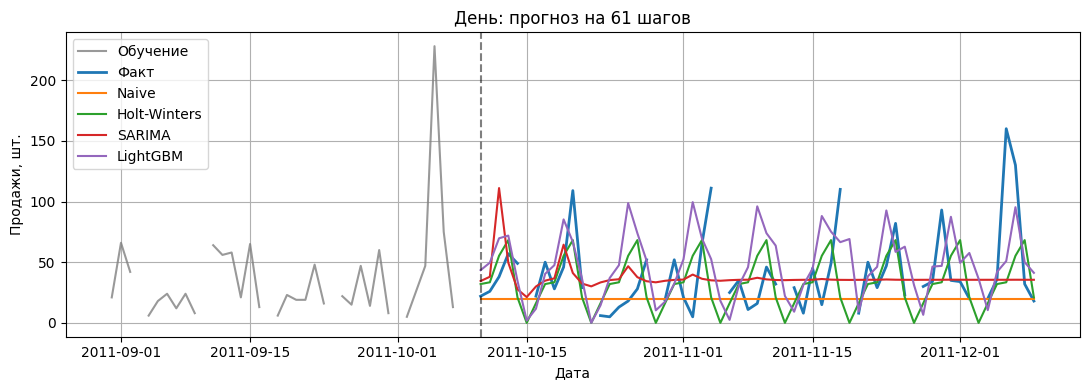

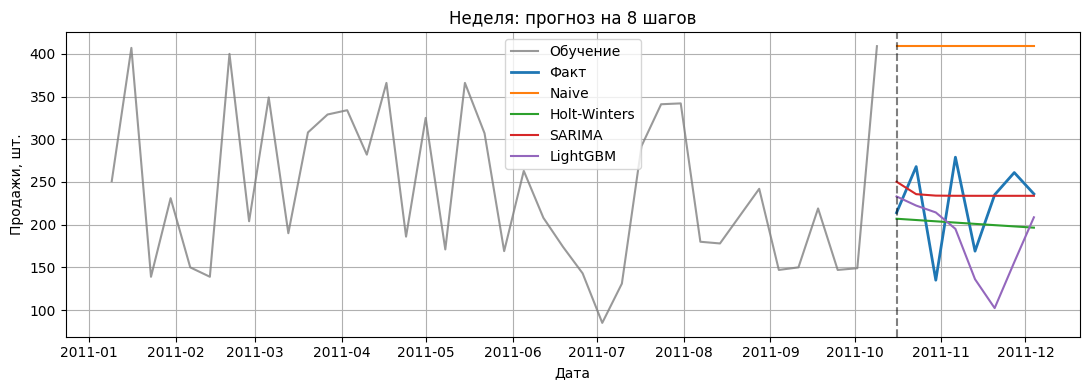

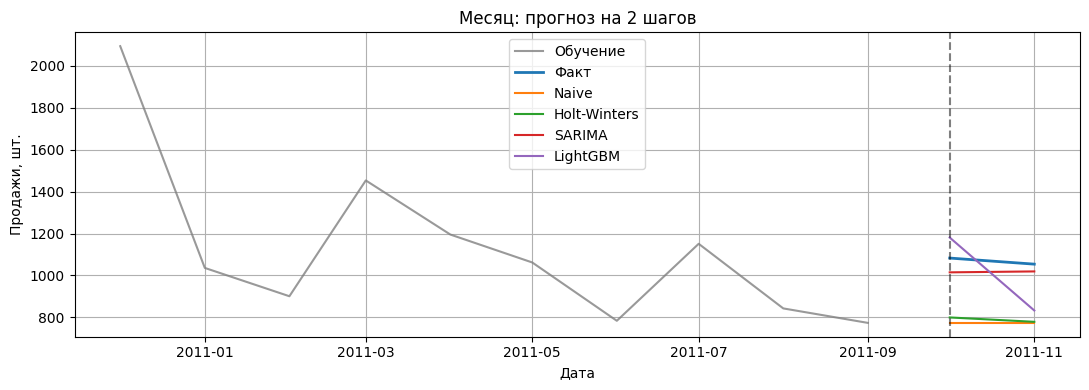

In [80]:
for name in series:
    fig, ax = plt.subplots(figsize=(11, 4))
    context = train[name].iloc[-min(40, len(train[name])):]
    ax.plot(context.index, context.to_numpy(), label='Обучение', color='grey', alpha=0.8)
    ax.plot(test[name].index, test[name].to_numpy(), label='Факт', linewidth=2)
    for model, forecast in predictions[name].items():
        ax.plot(test[name].index, forecast, label=model)
    ax.axvline(test[name].index[0], linestyle='--', color='black', alpha=0.5)
    ax.set(title=f'{name}: прогноз на {max(horizons[name])} шагов',
           xlabel='Дата', ylabel='Продажи, шт.')
    ax.legend()
    plt.tight_layout()
    plt.show()

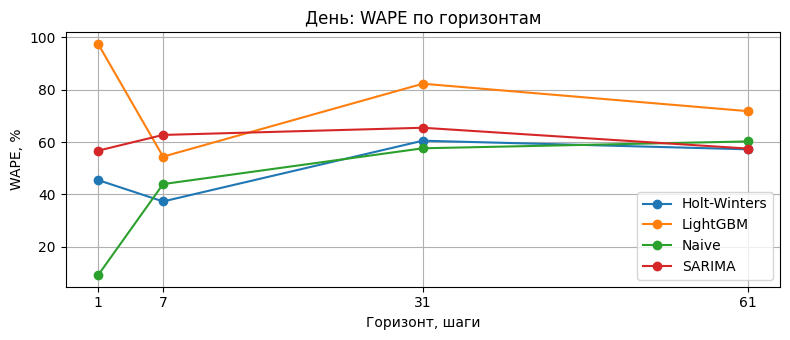

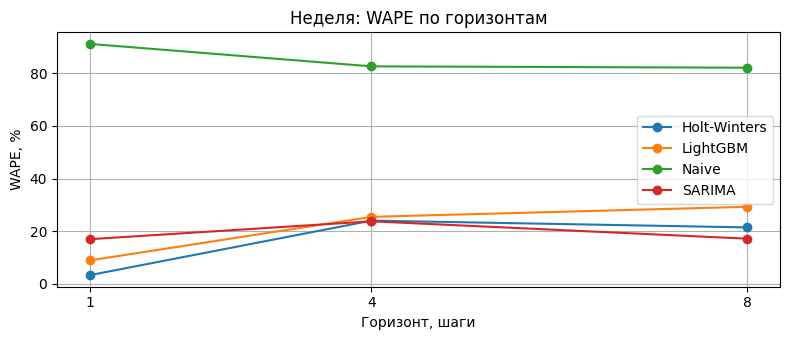

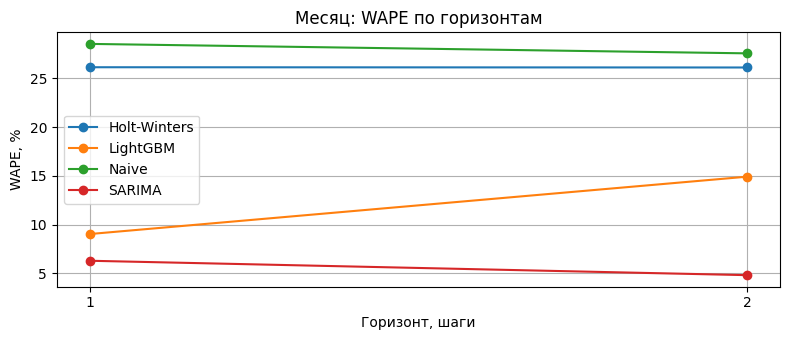

In [81]:
for name in series:
    subset = results[results['Частота'] == name]
    fig, ax = plt.subplots(figsize=(8, 3.5))
    for model, group in subset.groupby('Модель'):
        ax.plot(group['Горизонт'], group['WAPE, %'], marker='o', label=model)
    ax.set(title=f'{name}: WAPE по горизонтам', xlabel='Горизонт, шаги', ylabel='WAPE, %')
    ax.set_xticks(horizons[name])
    ax.legend()
    plt.tight_layout()
    plt.show()

In [82]:
print('Лучшие модели по MAE:')
for name in series:
    part = best[best['Частота'] == name]
    for row in part.itertuples(index=False):
        print(f'{name}, h={row[1]}: {row[2]}, MAE={row[3]:.2f}, WAPE={row[5]:.1f}%')

Лучшие модели по MAE:
День, h=1: Naive, MAE=2.00, WAPE=9.1%
День, h=7: Holt-Winters, MAE=13.30, WAPE=37.3%
День, h=31: Naive, MAE=20.44, WAPE=57.6%
День, h=61: Holt-Winters, MAE=23.47, WAPE=57.2%
Неделя, h=1: Holt-Winters, MAE=7.05, WAPE=3.3%
Неделя, h=4: SARIMA, MAE=53.19, WAPE=23.7%
Неделя, h=8: SARIMA, MAE=38.52, WAPE=17.1%
Месяц, h=1: SARIMA, MAE=68.09, WAPE=6.3%
Месяц, h=2: SARIMA, MAE=51.39, WAPE=4.8%


## 6. Улучшение относительно Naive

Считаю процентное изменение MAE относительно Naive: положительное значение означает улучшение.

Для прогноза на 1 день MAE Naive равна 2 на одном наблюдении. Из-за слишком больших процентов этот горизонт оставляю в таблице, но не показываю на дневном графике.


Изменение MAE относительно Naive (положительное значение — лучше):


Модель            Holt-Winters  LightGBM  Naive  SARIMA
Частота Горизонт                                       
День    1               -400.1    -973.0    0.0  -523.8
        7                 15.1     -23.9    0.0   -42.8
        31                -5.0     -42.9    0.0   -13.6
        61                 5.0     -19.2    0.0     4.5
Месяц   1                  8.4      68.4    0.0    78.0
        2                  5.3      45.9    0.0    82.5
Неделя  1                 96.4      90.2    0.0    81.4
        4                 70.9      69.2    0.0    71.2
        8                 73.9      64.4    0.0    79.1

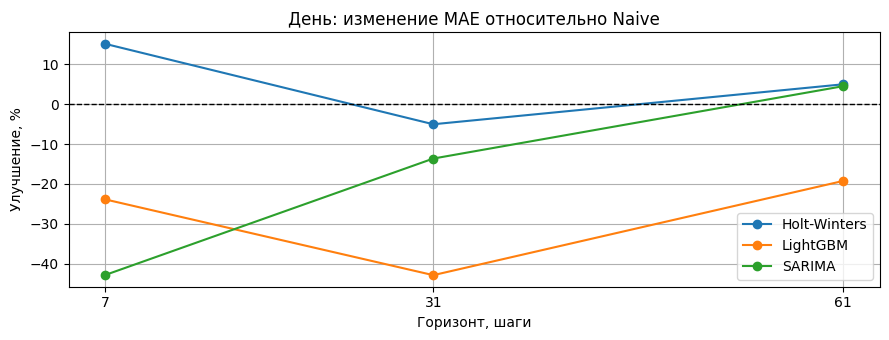

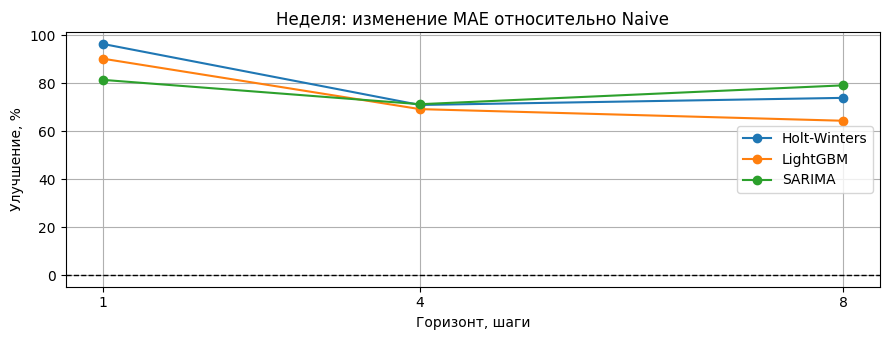

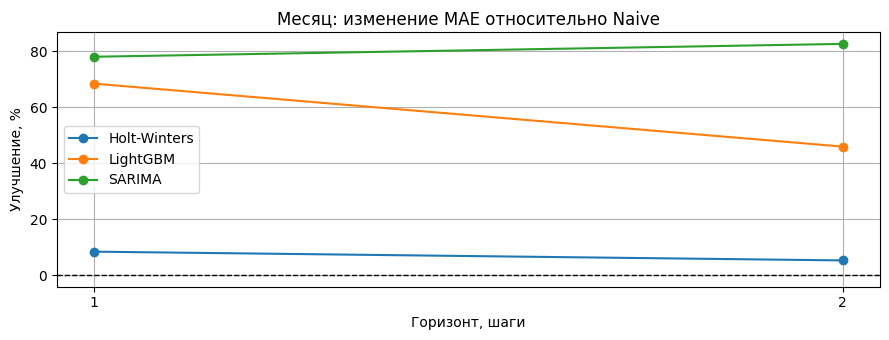

In [83]:
baseline = (results.loc[results['Модель'] == 'Naive', ['Частота', 'Горизонт', 'MAE']]
            .rename(columns={'MAE': 'MAE Naive'}))
gain = results.merge(baseline, on=['Частота', 'Горизонт'], how='left', validate='many_to_one')
gain['Улучшение к Naive, %'] = np.where(
    gain['MAE Naive'] > 0,
    100 * (gain['MAE Naive'] - gain['MAE']) / gain['MAE Naive'],
    np.nan
)
print('Изменение MAE относительно Naive (положительное значение — лучше):')
display(gain.pivot_table(index=['Частота', 'Горизонт'], columns='Модель',
                         values='Улучшение к Naive, %').round(1))
gain.to_csv('hw2_gain_vs_naive.csv', index=False)

for name in series:
    part = gain[(gain['Частота'] == name) & (gain['Модель'] != 'Naive')]
    if name == 'День':
        part = part[part['Горизонт'] > 1]
    fig, ax = plt.subplots(figsize=(9, 3.5))
    for model, group in part.groupby('Модель'):
        ax.plot(group['Горизонт'], group['Улучшение к Naive, %'], marker='o', label=model)
    ax.axhline(0, linestyle='--', color='black', linewidth=1)
    ax.set(title=f'{name}: изменение MAE относительно Naive',
           xlabel='Горизонт, шаги', ylabel='Улучшение, %')
    ax.set_xticks(sorted(part['Горизонт'].unique()))
    ax.legend()
    plt.tight_layout()
    plt.show()


## 7. Walk-forward-проверка

На обучающих рядах проверяю модели в четырёх непересекающихся дневных окнах по 61 дню и четырёх частично пересекающихся недельных окнах по 8 недель. В каждом окне использую только прошлые данные.

Сравниваю среднюю MAE и её стандартное отклонение по окнам. 


Точки начала проверки:


,Частота,Фолд,Дата начала
0,День,1,2011-02-08
1,День,2,2011-04-10
2,День,3,2011-06-10
3,День,4,2011-08-10
4,Неделя,1,2011-05-29
5,Неделя,2,2011-06-26
6,Неделя,3,2011-07-24
7,Неделя,4,2011-08-21


Средняя MAE и разброс по окнам: День


Модель,Holt-Winters,LightGBM,Naive,SARIMA
Горизонт,,,,
1,10.59,23.33,17.00,6.54
7,22.15,26.62,33.42,19.16
31,28.20,31.63,33.87,24.12
61,30.26,31.62,36.21,27.33


Модель,Holt-Winters,LightGBM,Naive,SARIMA
Горизонт,,,,
1,10.82,21.94,9.93,3.16
7,3.48,3.17,21.82,5.87
31,6.96,4.14,13.55,4.03
61,5.11,4.72,11.24,2.20


Средняя MAE и разброс по окнам: Неделя


Модель,Holt-Winters,LightGBM,Naive,SARIMA
Горизонт,,,,
1,100.25,110.68,62.50,91.76
4,85.91,97.10,73.44,79.52
8,88.02,102.35,89.00,83.30


Модель,Holt-Winters,LightGBM,Naive,SARIMA
Горизонт,,,,
1,59.33,39.78,51.01,40.69
4,32.40,18.09,26.95,25.92
8,35.16,23.18,26.70,13.67


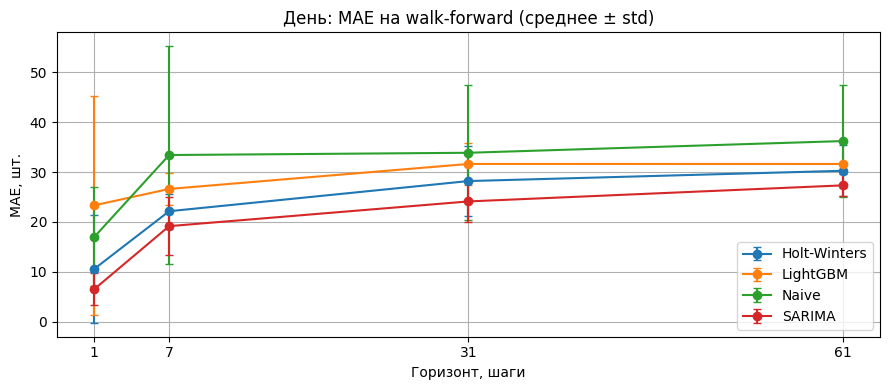

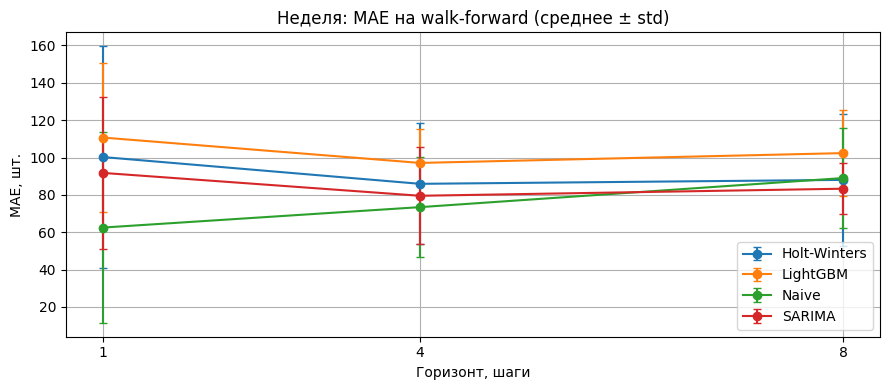

In [84]:
def walk_forward(s, name, starts):
    steps = max(horizons[name])
    rows = []
    for fold, start in enumerate(starts, 1):
        history = fill_train(s.iloc[:start], name)
        actual = s.iloc[start:start + steps].to_numpy()
        forecast = get_predictions(history, name, steps)
        for model, values in forecast.items():
            for h in horizons[name]:
                score = calc_metrics(actual[:h], values[:h])
                rows.append({'Частота': name, 'Фолд': fold,
                             'Дата начала': s.index[start], 'Модель': model,
                             'Горизонт': h, **score})
    return pd.DataFrame(rows)


origins = {'День': [69, 130, 191, 252], 'Неделя': [20, 24, 28, 32]}
for name, starts in origins.items():
    assert starts[-1] + max(horizons[name]) <= len(train[name])

wf = pd.concat([walk_forward(train[name], name, starts)
                for name, starts in origins.items()], ignore_index=True)
wf_summary = (wf.groupby(['Частота', 'Горизонт', 'Модель'], as_index=False)
              .agg(mean_MAE=('MAE', 'mean'), std_MAE=('MAE', 'std'),
                   folds=('MAE', 'count'), mean_WAPE=('WAPE, %', 'mean')))

print('Точки начала проверки:')
display(wf[['Частота', 'Фолд', 'Дата начала']].drop_duplicates().reset_index(drop=True))
for name in origins:
    print(f'Средняя MAE и разброс по окнам: {name}')
    view = wf_summary[wf_summary['Частота'] == name]
    display(view.pivot(index='Горизонт', columns='Модель', values='mean_MAE').round(2))
    display(view.pivot(index='Горизонт', columns='Модель', values='std_MAE').round(2))

wf.to_csv('hw2_walk_forward_folds.csv', index=False)
wf_summary.to_csv('hw2_walk_forward.csv', index=False)

for name in origins:
    part = wf_summary[wf_summary['Частота'] == name]
    fig, ax = plt.subplots(figsize=(9, 4))
    for model, group in part.groupby('Модель'):
        ax.errorbar(group['Горизонт'], group['mean_MAE'], yerr=group['std_MAE'],
                    marker='o', capsize=3, label=model)
    ax.set(title=f'{name}: MAE на walk-forward (среднее ± std)',
           xlabel='Горизонт, шаги', ylabel='MAE, шт.')
    ax.set_xticks(horizons[name])
    ax.legend()
    plt.tight_layout()
    plt.show()


## 8. Анализ ошибок

На максимальном горизонте оцениваю среднюю ошибку со знаком и 90-й процентиль абсолютной ошибки. Положительная средняя ошибка означает недооценку продаж, отрицательная - переоценку.

Также показываю ошибки по датам и важность признаков LightGBM. На месячном тесте только два наблюдения.


Ошибки на максимальном горизонте:


,Частота,Модель,N,Смещение,90% абсолютной ошибки
0,День,Naive,53,21.00,70.80
1,День,Holt-Winters,53,2.92,48.37
2,День,SARIMA,53,3.11,65.82
3,День,LightGBM,53,-10.39,57.27
4,Неделя,Naive,8,-184.38,250.20
5,Неделя,Holt-Winters,8,22.93,71.22
6,Неделя,SARIMA,8,-11.50,75.06
7,Неделя,LightGBM,8,41.13,113.23
8,Месяц,Naive,2,294.50,306.10
9,Месяц,Holt-Winters,2,279.00,282.26


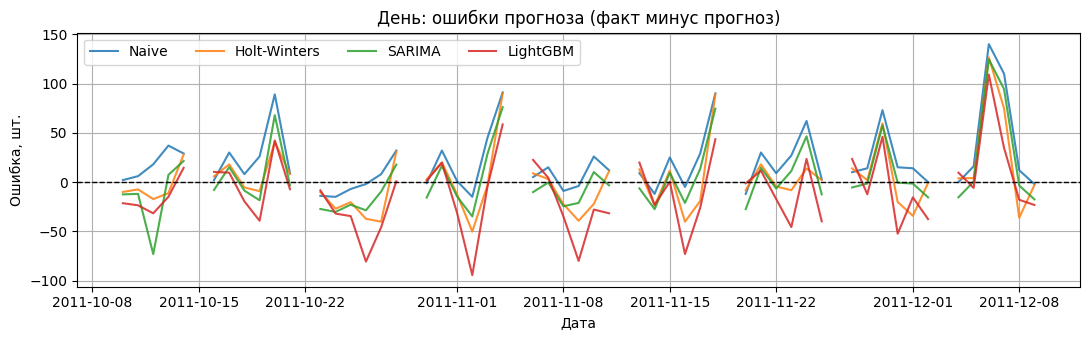

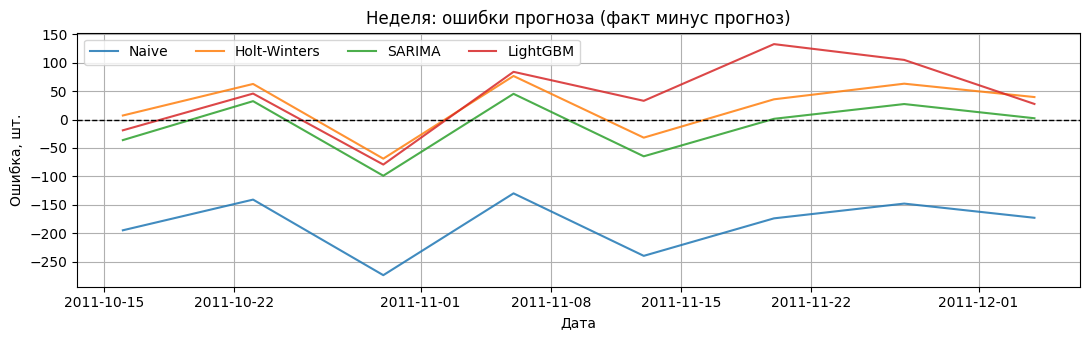

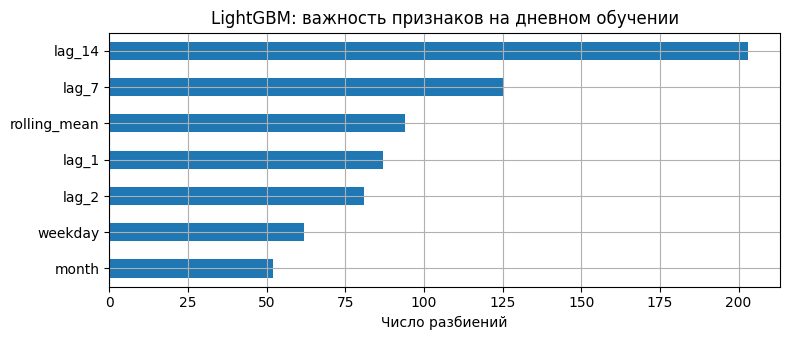

In [85]:
errors = []
for name in series:
    actual = test[name].to_numpy(dtype=float)
    for model, forecast in predictions[name].items():
        valid = np.isfinite(actual) & np.isfinite(forecast)
        residual = actual[valid] - forecast[valid]
        errors.append({'Частота': name, 'Модель': model, 'N': len(residual),
                       'Смещение': np.mean(residual),
                       '90% абсолютной ошибки': np.quantile(np.abs(residual), 0.9)})
errors = pd.DataFrame(errors)
print('Ошибки на максимальном горизонте:')
display(errors.round(2))
errors.to_csv('hw2_residual_diagnostics.csv', index=False)

for name in ['День', 'Неделя']:
    actual = test[name]
    fig, ax = plt.subplots(figsize=(11, 3.5))
    for model, forecast in predictions[name].items():
        ax.plot(actual.index, actual.to_numpy() - forecast, label=model, alpha=0.85)
    ax.axhline(0, linestyle='--', color='black', linewidth=1)
    ax.set(title=f'{name}: ошибки прогноза (факт минус прогноз)',
           xlabel='Дата', ylabel='Ошибка, шт.')
    ax.legend(ncol=4)
    plt.tight_layout()
    plt.show()

model, names = fit_lightgbm(train_ready['День'], 'День')
importance = (pd.Series(model.feature_importances_, index=names)
              .sort_values(ascending=False))
fig, ax = plt.subplots(figsize=(8, 3.5))
importance.sort_values().plot.barh(ax=ax)
ax.set(title='LightGBM: важность признаков на дневном обучении',
       xlabel='Число разбиений')
plt.tight_layout()
plt.show()


## 9. Выводы

На основном дневном тесте Naive показала наименьшую MAE на 1 и 31 день (2,00 и 20,44), Holt–Winters : на 7 и 61 день (13,30 и 23,47). Для 61 дня WAPE составила 57,24%; на горизонте 1 день оценка основана на одном наблюдении.

На недельном тесте лидировали Holt–Winters на 1 неделю (MAE 7,05) и SARIMA на 4 и 8 недель (53,19 и 38,52). На месячном ряду лучшей оказалась SARIMA (68,09 и 51,39), но для неё доступно всего 10 месяцев обучения и 2 месяца теста.

В дневной walk-forward-проверке SARIMA получила минимальную среднюю MAE на всех горизонтах (6,54; 19,16; 24,12; 27,33). На недельной проверке лидировали Naive на 1 и 4 недели (62,50 и 73,44) и SARIMA на 8 недель (83,30)=> результаты зависят от периода оценки.

Сложные модели не всегда превосходят Naive. На недельном тесте она часто завышала продажи; у LightGBM самыми важными оказались лаговые признаки.

Основные ограничения - пропущенные даты, короткий месячный ряд, фиксированные параметры и всего четыре окна walk-forward, частично пересекающиеся для недельного ряда. Однозначно лучшую модель выбрать нельзя.
